### **Student Information**
GitHub ID:mrinvisablelife

Kaggle name:Bai

Kaggle private scoreboard snapshot: 

*Note: I sincerely apologize for missing the in-class Kaggle competition deadline due to my own oversight, so I do not have a private leaderboard screenshot. Even so, I still completed the competition pipeline and report to make up for this careless mistake as best I can. Below are the code and results I developed for Lab 2—thank you for your time and understanding.*
![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

For preprocessing, I downloaded `final_posts.json`, `data_identification.csv`, `emotion.csv`, and `sampleSubmission.csv` from Kaggle. Using `pandas` to load the files, I **split the data into `train` and `test` sets by `post_id`**. I then **merged the `train` set with `emotion.csv`** to attach the corresponding emotion labels, and **aligned the `test` set with `sampleSubmission.csv`** so the output matches the required submission format. After merging, I inspected the sample count of each emotion class to check whether additional handling was needed, and concluded that **no extra resampling (such as random sampling) was necessary**.

To make the training signal clearer, I **cleaned dataset noise while preserving emotional cues**:

1. **Removed web links and URL tags (`##URL##`)** that carry no emotional information.
2. **Replaced usernames and names with uniform tokens** (`@<username>` to `@user`, `[NAME]` to `someone`) so the model is not affected by rare tokens while **preserving sentence grammar**.
3. **Collapsed long repeated-word loops** (e.g., repeated words from noisy machine translations) so abnormal posts do not waste token length.
4. **Kept original capitalization and punctuation**, since uppercase words (like "WTF!" or "SHOCKED") provide strong intensity signals for emotion models.

Finally, after cleaning the text, I split the original `train` data into a **70/30 stratified train/validation split (2,352 train / 1,008 validation)** for subsequent training and evaluation.

### 1.2 Feature Engineering Steps

Because keyword matching alone was not effective enough, I adopted AI's suggestion to convert each cleaned text into **three complementary feature sets that run efficiently on CPU**:

- **Ekman Emotion Features (`j-hartmann/emotion-english-distilroberta-base`):** Used as a **frozen encoder** to extract **7 emotion logits** (the six target emotions plus neutral), followed by masked mean pooling over the last hidden layer to obtain a **768-dimensional sentence embedding**.
- **Fine-Grained Emotion Features (`SamLowe/roberta-base-go_emotions`):** Used as a second **frozen encoder** to extract **28 fine-grained emotion logits** (such as annoyance, disapproval, and nervousness) along with another **768-dimensional pooled embedding**. This helps distinguish harder cases, such as posts that carry multiple emotions.
- **TF-IDF (`TfidfVectorizer`):** Extracted **unigrams and bigrams** with sublinear TF scaling (top 10,000 features) to capture explicit emotion keywords and short phrases.

To **speed up CPU computation**, texts were sorted by length and batched with **dynamic padding (`max_length=96`)**, then restored to their original order afterward. To **prevent data leakage**, both `TfidfVectorizer` and `StandardScaler` were fit **strictly on the training subset**, while both 768-dimensional embeddings were **L2-normalized**. This produced a **1,571-dimensional dense emotion matrix** for the neural network and an **11,571-dimensional combined sparse-and-dense matrix** (emotion features + TF-IDF) for the linear classifier.

### 1.3 Explanation of Your Model

Building on the methods from Lab 2 and AI's suggestions, I implemented a **two-model blended architecture**:

1. **Linear SVM (`LinearSVC`):** Linear SVM excels at finding decision boundaries in high-dimensional sparse-and-dense spaces. Trained on the **dual emotion features + TF-IDF**, I set **`class_weight="balanced"`** to penalize mistakes on minority emotions (such as `fear` and `disgust`) more heavily, and tuned **`C=0.15`** for stronger regularization to reduce overfitting and improve **Macro F1**.
2. **Multi-Layer Perceptron (`MLPClassifier`):** Trained on the **dense dual emotion features** using two hidden layers **`(128, 64)`** to learn non-linear combinations across the 35 emotion logits and sentence embeddings, with **L2 regularization (`alpha=0.1`)** and **`early_stopping=True`** to prevent overfitting.
3. **Equal-Weight Score Blending:** Combining the two models above. Since SVM outputs raw margin scores (`decision_function`) while MLP outputs probabilities (`predict_proba`), I applied **row-wise Z-score normalization** to bring both onto the same scale, averaged them equally (**`0.5 * SVM + 0.5 * MLP`**), and selected the highest-scoring emotion as the final prediction.

**Why I designed it this way:** The initial `MiniLM + Naive Bayes` baseline was unimpressive (**Macro F1 `0.5213`**), and switching to `MiniLM + LinearSVM` only added about `0.02`. After several rounds of tuning, it became clear that `MiniLM` has a ceiling for capturing nuanced emotion cues. Replacing it with emotion-specific frozen encoders (**`Ekman DistilRoBERTa + GoEmotions RoBERTa`**) brought a major jump (**Macro F1 `0.6428`**), though still slightly short of my `0.65` target. I therefore blended the linear model (strong at TF-IDF keywords) with the non-linear MLP (strong at dense emotion feature interactions). Repeated tests confirmed that the blend is more robust and predicts emotions more consistently (**Macro F1 `0.6505`**, **Accuracy `0.6746`**) while still running smoothly on CPU, so I adopted it as the final competition pipeline.

Below is the validation confusion matrix for the final model:

![Validation Confusion Matrix](./pics/confusion_matrix.png)

Looking at the per-class scores and confusion matrix, **all six emotions exceed `0.50`**: `joy` (`0.79`) and `sadness` (`0.72`) perform best, followed by `fear` (`0.68`), `anger` (`0.62`), and `surprise` (`0.60`). `disgust` remains the hardest class (`0.50`), as its wording frequently overlaps with `anger` and sarcastic `joy`.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

- **Prompt 1 — Initial strategy planning:** I uploaded the four competition files and asked AI to inspect the data format and rules, as well as recommend suitable methods.
  - *Suggestions received & decision:* AI initially proposed a soft-voting ensemble (`LogisticRegression` + calibrated SVM), character n-grams, and 5-fold cross-validation. Considering that my local Jupyter environment runs on **CPU**, I **rejected that draft** and instead provided the methods taught in class. Assuming that **`MiniLM`** would generalize better at capturing emotional cues on unseen posts, I consolidated the course code and asked AI to refactor it into a comparison table (similar to Section 7) to select the best approach by **Macro F1**, prioritizing **`MiniLM + Naive Bayes`** first.
- **Prompt 2 — Macro F1 fell short of expectations:** Seeing that the initial Macro F1 was lower than expected, I followed AI's suggestion to test the runner-up **`Linear SVM`**, suspecting that overfitting in the initial comparison table had held its score back. After **tuning its hyperparameters**, results confirmed that **`MiniLM + Linear SVM`** outperformed `MiniLM + Naive Bayes`.
- **Prompt 3 — Reaching the target score:** Since `MiniLM + Linear SVM` only reached **`0.54`**—well below my **`0.65`** target—I looked for stronger replacements for `MiniLM`. I first adopted AI's suggestion to **fine-tune `DeBERTa-v3` in PyTorch** (with early stopping and class weights), but testing confirmed it was **impractical to run on CPU**. After reviewing lighter alternatives, I decided to replace `MiniLM` with two finer-grained, emotion-specific models—**`j-hartmann/emotion-english-distilroberta-base`** and **`SamLowe/roberta-base-go_emotions`**—to optimize performance.
---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [12]:
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

os.environ["TOKENIZERS_PARALLELISM"] = "false"
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on: {DEVICE}")

# Load competition files
DATA_DIR = Path("data/competition")
with open(DATA_DIR / "final_posts.json", "r", encoding="utf-8") as f:
    posts_df = pd.DataFrame(json.load(f))

id_df = pd.read_csv(DATA_DIR / "data_identification.csv")
emo_df = pd.read_csv(DATA_DIR / "emotion.csv")
sub_template = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

# Merge posts with train/test split and labels
df = posts_df.merge(id_df, on="post_id", how="inner")
train_df = df[df["set"] == "train"].merge(emo_df, on="post_id", how="inner").reset_index(drop=True)
test_df = sub_template[["post_id"]].merge(df[df["set"] == "test"], on="post_id", how="left")

# Clean placeholders & repeated translation noise while keeping capitalization/punctuation
def clean_text(text):
    text = str(text)
    text = re.sub(r"#+URL#+", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"@<username>", "@user", text, flags=re.IGNORECASE)
    text = re.sub(r"\[NAME\]", "someone", text, flags=re.IGNORECASE)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\b(\w+)(?:\s+\1){2,}\b", r"\1 \1", text, flags=re.IGNORECASE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Stratified 70 / 30 train / validation split
all_idx = np.arange(len(train_df))
tr_idx, va_idx = train_test_split(
    all_idx,
    test_size=0.3,
    random_state=SEED,
    stratify=train_df["label"],
)
y_train = train_df["label"].iloc[tr_idx].values
y_val = train_df["label"].iloc[va_idx].values

print(f"70/30 Split -> Train: {len(tr_idx)}, Validation: {len(va_idx)}, Test: {len(test_df)}")
print("\nTraining class distribution:\n", train_df["label"].value_counts())

Running on: cpu
70/30 Split -> Train: 2352, Validation: 1008, Test: 1440

Training class distribution:
 label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


## 2. Feature Engineering Steps

In [13]:
import time
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# Frozen pretrained emotion feature extractor (length-sorted dynamic padding for fast CPU inference)
def extract_emotion_features(model_name, texts, batch_size=64, max_length=96):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).float().to(DEVICE)
    model.eval()

    texts = list(texts)
    order = np.argsort([len(t) for t in texts])
    sorted_texts = [texts[i] for i in order]

    logits_list, emb_list = [], []
    with torch.no_grad():
        for start in range(0, len(sorted_texts), batch_size):
            batch_texts = sorted_texts[start : start + batch_size]
            enc = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt",
            ).to(DEVICE)
            out = model(**enc, output_hidden_states=True)
            logits_list.append(out.logits.cpu().numpy())

            # Masked mean pooling over the last hidden layer
            last_hidden = out.hidden_states[-1]
            mask = enc["attention_mask"].unsqueeze(-1).float()
            pooled = (last_hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
            emb_list.append(pooled.cpu().numpy())

    inv_order = np.argsort(order)
    return np.vstack(logits_list)[inv_order], np.vstack(emb_list)[inv_order]

# Extract frozen emotion features once for both train and test sets
all_texts = train_df["clean_text"].tolist() + test_df["clean_text"].tolist()
n_train = len(train_df)

t0 = time.time()
ekman_logits, ekman_embs = extract_emotion_features(
    "j-hartmann/emotion-english-distilroberta-base", all_texts
)
print(f"Ekman DistilRoBERTa done in {time.time() - t0:.1f}s | logits: {ekman_logits.shape}")

t1 = time.time()
go_logits, go_embs = extract_emotion_features(
    "SamLowe/roberta-base-go_emotions", all_texts
)
print(f"GoEmotions RoBERTa done in {time.time() - t1:.1f}s | logits: {go_logits.shape}")

# Separate train and test frozen features
tr_all_ek_log, te_ek_log = ekman_logits[:n_train], ekman_logits[n_train:]
tr_all_ek_emb, te_ek_emb = ekman_embs[:n_train], ekman_embs[n_train:]
tr_all_go_log, te_go_log = go_logits[:n_train], go_logits[n_train:]
tr_all_go_emb, te_go_emb = go_embs[:n_train], go_embs[n_train:]

# Helper to fit TF-IDF & scalers strictly on training subset (prevents data leakage)
def build_feature_matrices(tr_texts, ev_texts, tr_ek_l, ev_ek_l, tr_go_l, ev_go_l, tr_ek_e, ev_ek_e, tr_go_e, ev_go_e):
    tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
    X_tr_tf = tfidf.fit_transform(tr_texts)
    X_ev_tf = tfidf.transform(ev_texts)

    sc_ek = StandardScaler()
    X_tr_ek_l = sc_ek.fit_transform(tr_ek_l)
    X_ev_ek_l = sc_ek.transform(ev_ek_l)

    sc_go = StandardScaler()
    X_tr_go_l = sc_go.fit_transform(tr_go_l)
    X_ev_go_l = sc_go.transform(ev_go_l)

    X_tr_dual = np.hstack([X_tr_ek_l, X_tr_go_l, normalize(tr_ek_e), normalize(tr_go_e)])
    X_ev_dual = np.hstack([X_ev_ek_l, X_ev_go_l, normalize(ev_ek_e), normalize(ev_go_e)])

    X_tr_full = hstack([csr_matrix(X_tr_dual), X_tr_tf]).tocsr()
    X_ev_full = hstack([csr_matrix(X_ev_dual), X_ev_tf]).tocsr()
    return X_tr_dual, X_ev_dual, X_tr_full, X_ev_full

# Build 70/30 validation matrices
X_tr_dual, X_va_dual, X_tr_full, X_va_full = build_feature_matrices(
    train_df["clean_text"].iloc[tr_idx], train_df["clean_text"].iloc[va_idx],
    tr_all_ek_log[tr_idx], tr_all_ek_log[va_idx],
    tr_all_go_log[tr_idx], tr_all_go_log[va_idx],
    tr_all_ek_emb[tr_idx], tr_all_ek_emb[va_idx],
    tr_all_go_emb[tr_idx], tr_all_go_emb[va_idx],
)
print(f"Validation matrices ready -> Dense: {X_tr_dual.shape}, Combined (+TF-IDF): {X_tr_full.shape}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Ekman DistilRoBERTa done in 39.3s | logits: (4800, 7)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

GoEmotions RoBERTa done in 80.4s | logits: (4800, 28)
Validation matrices ready -> Dense: (2352, 1571), Combined (+TF-IDF): (2352, 11571)


## 3. Model Implementation Steps

Validation Accuracy: 0.6746 | Validation Macro F1: 0.6505

              precision    recall  f1-score   support

       anger     0.6368    0.5990    0.6173       202
     disgust     0.5701    0.4485    0.5021       136
        fear     0.7179    0.6437    0.6788        87
         joy     0.7417    0.8517    0.7929       263
     sadness     0.6777    0.7606    0.7168       188
    surprise     0.6250    0.5682    0.5952       132

    accuracy                         0.6746      1008
   macro avg     0.6616    0.6453    0.6505      1008
weighted avg     0.6683    0.6746    0.6686      1008



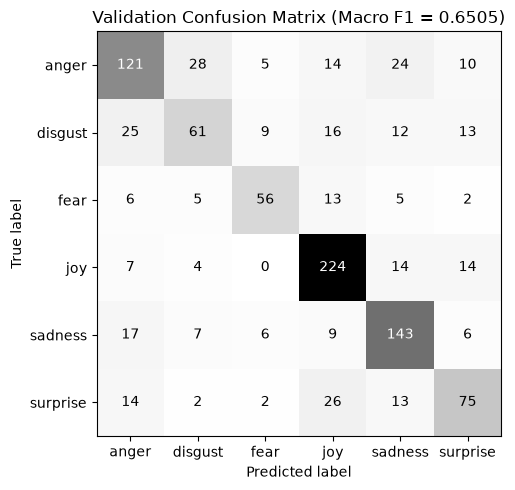

Saved submission.csv successfully!
   post_id     label
0  xyzx9jp  surprise
1  l3vzzxt     anger
2  g680iug   sadness
3  m4t8bp6       joy
4  ai3al6e  surprise

Predicted label distribution:
 label
joy         412
anger       336
sadness     280
surprise    179
disgust     133
fear        100
Name: count, dtype: int64


In [14]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

def zscore_rows(arr):
    return (arr - arr.mean(axis=1, keepdims=True)) / (arr.std(axis=1, keepdims=True) + 1e-9)

def fit_and_blend(X_tr_full_in, X_ev_full_in, X_tr_dual_in, X_ev_dual_in, y_tr_in):
    # Model 1: Linear SVM on Dual Emotion Features + TF-IDF
    svm = LinearSVC(C=0.15, class_weight="balanced", dual=True, max_iter=3000, random_state=SEED)
    svm.fit(X_tr_full_in, y_tr_in)
    svm_scores = zscore_rows(svm.decision_function(X_ev_full_in))

    # Model 2: MLP with Early Stopping on Dual Emotion Features
    mlp = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        alpha=0.1,
        max_iter=150,
        early_stopping=True,
        random_state=SEED,
    )
    mlp.fit(X_tr_dual_in, y_tr_in)
    mlp_scores = zscore_rows(mlp.predict_proba(X_ev_dual_in))

    # Equal-weight score blend (0.5 SVM + 0.5 MLP)
    blend = 0.5 * svm_scores + 0.5 * mlp_scores
    return svm.classes_[blend.argmax(axis=1)]

# 1. Evaluate on 70/30 stratified validation split
val_preds = fit_and_blend(X_tr_full, X_va_full, X_tr_dual, X_va_dual, y_train)
val_acc = accuracy_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds, average="macro")

print(f"Validation Accuracy: {val_acc:.4f} | Validation Macro F1: {val_f1:.4f}\n")
print(classification_report(y_val, val_preds, digits=4))

# Save monochrome confusion matrix for the report
labels_sorted = sorted(train_df["label"].unique())
cm = confusion_matrix(y_val, val_preds, labels=labels_sorted)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_sorted)
disp.plot(ax=ax, cmap="Greys", colorbar=False)
ax.set_title(f"Validation Confusion Matrix (Macro F1 = {val_f1:.4f})")
plt.tight_layout()
Path("pics").mkdir(exist_ok=True)
plt.savefig("pics/confusion_matrix.png", dpi=150)
plt.show()

# 2. Retrain on 100% of training data (3,360 posts) and generate submission.csv
X_full_dual, X_test_dual, X_full_all, X_test_all = build_feature_matrices(
    train_df["clean_text"], test_df["clean_text"],
    tr_all_ek_log, te_ek_log,
    tr_all_go_log, te_go_log,
    tr_all_ek_emb, te_ek_emb,
    tr_all_go_emb, te_go_emb,
)
test_preds = fit_and_blend(X_full_all, X_test_all, X_full_dual, X_test_dual, train_df["label"].values)

# Format submission strictly matching sampleSubmission.csv
submission = pd.DataFrame({
    sub_template.columns[0]: test_df["post_id"].astype(str),
    sub_template.columns[1]: pd.Series(test_preds).astype(str),
})

assert list(submission.columns) == list(sub_template.columns), "Column mismatch!"
assert len(submission) == len(sub_template), "Row count mismatch!"
assert (submission.iloc[:, 0].values == sub_template.iloc[:, 0].values).all(), "ID order mismatch!"
assert submission.isna().sum().sum() == 0, "Missing values found!"

submission.to_csv("submission.csv", index=False)
print("Saved submission.csv successfully!")
print(submission.head(5))
print("\nPredicted label distribution:\n", submission.iloc[:, 1].value_counts())